# Bullet Brawl backtest: how much Gaussian smoothing?

Walk-forward test of the Bullet Brawl Monte Carlo. Each event is predicted only from events before it.
The three models share the same player pool, attendance estimate and skill history, and differ only in the
noise added to each sampled score:

| Model | Noise sigma |
|---|---|
| `score` | none |
| `score_smooth_3` | 3 score points |
| `score_smooth_10` | 10 score points |

Skill and attendance decay match Titled Tuesday (0.96 and 0.75 per week). A player with zero games counts as
not attending, in both the history and the results. Bullet Brawl has no season shift.

**Reading the scores.** Log loss and Brier are lower-is-better. `p_top` is the tradable probability
(`p_participate` x `P_topN_given_play`).

In [1]:
import contextlib
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import rankdata

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT), str(ROOT / 'scripts')]

from run_backtest import PROFILES, run_backtest
from src import backtest_runs as br
from src.config import DB_PATH
from src.markets import BULLET_BRAWL
from src.pipeline import next_tourn_date, run_raw

pd.set_option('display.width', 160, 'display.max_columns', 40, 'display.max_rows', 200)

MODEL_STYLES = {
    'score':           {'color': '#2a78d6', 'marker': 'o'},
    'score_smooth_3':  {'color': '#1baf7a', 'marker': '^'},
    'score_smooth_10': {'color': '#eb6834', 'marker': 's'},
}
MODELS = list(MODEL_STYLES)
SMOOTHED = MODELS[1:]
NS = [1, 3, 5, 8, 10]
TRADED = [1, 3, 5, 8]
MUTED, GRID, REFERENCE = '#52514e', '#e4e3df', '#8a8983'
EPS = 1e-6


def label_n(n):
    return 'Winner' if n == 1 else f'Top {n}'


plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRID,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False,
    'lines.linewidth': 2, 'lines.markersize': 7, 'font.size': 10,
})

## 1. Run the backtest

Reuses the latest completed run with these settings. Set `RERUN = True` to run it again (about an hour at
100,000 simulations); progress goes to `data/bullet_brawl_backtest.log`.

In [2]:
MARKET = BULLET_BRAWL.slug
BACKTEST_START = PROFILES[MARKET].start
N_SIMS = 100_000
RERUN = False

runs = br.list_runs()
print('.')
matching = runs[(runs['market'] == MARKET) & (runs['status'] == 'completed')
                & (runs['start_date'] == BACKTEST_START) & (runs['n_sims'] == N_SIMS)]
print('.')
if RERUN or matching.empty:
    print('.')
    with open(ROOT / 'data' / 'bullet_brawl_backtest.log', 'w', encoding='utf-8', buffering=1) as log, \
            contextlib.redirect_stdout(log):
        RUN_ID = run_backtest(market=MARKET, start_date=BACKTEST_START, n_sims=N_SIMS,
                              notes='Bullet Brawl gaussian sigma 0 / 3 / 10')
else:
    RUN_ID = int(matching.index[0])

print(f'Run {RUN_ID}')
br.run_settings(RUN_ID)

.
.
Run 9


{'attendance_start': None,
 'base_seed': 42,
 'data_cutoff': '2020-01-01',
 'min_appearances': 5,
 'min_participation_rate': 0.005,
 'n_sims': 100000,
 'n_values': [1, 3, 5, 8, 10],
 'noise_sigma': {'score': 0.0,
  'score_smooth_10': 100000.0,
  'score_smooth_3': 30000.0},
 'participation_decay': 0.75,
 'played_filter': 'games > 0',
 'sample': None,
 'season_shift_applied': False,
 'skill_decay': 0.96,
 'start_date': '2024-01-06'}

In [5]:
predictions = br.load_predictions([RUN_ID])
scored = br.score_predictions(predictions)
scored['year'] = scored['tourn_date'].str[:4]
summary = br.summarize(scored).loc[RUN_ID]

pools = predictions.groupby(['tourn_date', 'model']).size().unstack('model')[MODELS]
assert (pools.nunique(axis=1) == 1).all(), 'Pool sizes differ across models'
print(f"{pools.shape[0]} events, {predictions['tourn_date'].min()} to {predictions['tourn_date'].max()}")
print(f"Pool size per event: {pools['score'].min()} to {pools['score'].max()}, the same for all three models")

147 events, 2024-01-06 to 2026-11-07
Pool size per event: 247 to 1252, the same for all three models


## 2. How big is a sigma of 3 or 10?

Week-to-week score variation of the regulars, and the score it takes to finish near the top, since 2024. A
sigma is small when it is well below a player's own spread, as the resampled history already carries that.

In [3]:
with sqlite3.connect(DB_PATH) as conn:
    standings = pd.read_sql_query(
        "SELECT date, username, rank, score FROM bullet_brawl_standings WHERE games > 0 AND date >= ?",
        conn, params=(BACKTEST_START,))

finish = pd.DataFrame({label_n(n): standings[standings['rank'] == n]['score'].describe()[['mean', 'std', 'min', 'max']]
                       for n in NS}).T
display(finish.round(1))

regulars = (standings.groupby('username')['score'].agg(events='size', mean_score='mean', score_sd='std')
            .query('events >= 30').sort_values('mean_score', ascending=False).head(10))
display(regulars.round(1))

,mean,std,min,max
Winner,209.9,45.5,147.0,320.0
Top 3,178.0,35.7,131.0,268.0
Top 5,160.1,27.1,124.0,204.0
Top 8,139.8,18.2,108.0,177.0
Top 10,128.7,13.5,102.0,162.0


,events,mean_score,score_sd
username,,,
hikaru,83,205.6,54.9
danielnaroditsky,77,199.7,58.2
penguingm1,78,183.6,46.8
oleksandr_bortnyk,132,169.5,40.7
gurelediz,65,161.6,35.6
christopheryoo,37,157.3,39.8
ghandeevam2003,32,141.9,47.8
wonderfultime,109,139.9,42.7
hansen,34,138.4,34.3


## 3. Accuracy by model

Log loss and Brier on the tradable probability, then log loss given that the player attended, which isolates
the skill model. `hit_capture` is the share of real top-N finishes that went to someone in the prediction pool.

In [4]:
def by_model(column):
    table = summary[column].unstack('model')[MODELS]
    table.index = [label_n(n) for n in table.index]
    return table.assign(best=table.idxmin(axis=1))


for title, column, digits in (('Log loss', 'log_loss', 6), ('Brier', 'brier', 6),
                              ('Log loss given attended', 'log_loss_given_play', 5)):
    print(title)
    display(by_model(column).round(digits))

display(summary.xs('score', level='model')[['events', 'predicted_per_event', 'actual_per_event', 'hit_capture']].round(3))

Log loss


NameError: name 'summary' is not defined

## 4. Is the difference real?

Each point is the mean change in total log loss per event against `score`, with a 95% interval across events.
Left of zero is better than `score`. An interval crossing zero means the data can't separate that model from no
smoothing. `events_better` is the share of events where the smoothed model beat `score`.

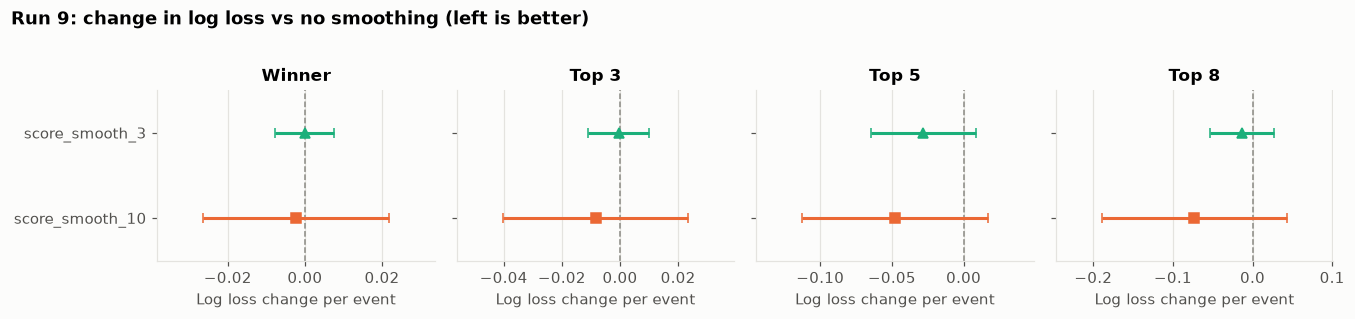

Tradable probability


,n,model,mean_change,ci_low,ci_high,events_better
0,1,score_smooth_3,-0.0001,-0.0078,0.0077,0.4490
1,1,score_smooth_10,-0.0023,-0.0263,0.0217,0.3605
2,3,score_smooth_3,-0.0004,-0.0109,0.0101,0.4694
3,3,score_smooth_10,-0.0084,-0.0403,0.0234,0.3605
4,5,score_smooth_3,-0.0280,-0.0647,0.0087,0.5170
5,5,score_smooth_10,-0.0479,-0.1124,0.0167,0.4422
6,8,score_smooth_3,-0.0132,-0.0528,0.0263,0.5442
7,8,score_smooth_10,-0.0729,-0.1892,0.0433,0.4286
8,10,score_smooth_3,-0.0268,-0.0535,-0.0001,0.5170
9,10,score_smooth_10,-0.1204,-0.2482,0.0074,0.4082


Given attended


,n,model,mean_change,ci_low,ci_high,events_better
0,1,score_smooth_3,-0.0001,-0.0078,0.0077,0.4762
1,1,score_smooth_10,-0.0004,-0.0241,0.0233,0.3810
2,3,score_smooth_3,-0.0038,-0.0147,0.0071,0.4966
3,3,score_smooth_10,-0.0092,-0.0416,0.0232,0.3810
4,5,score_smooth_3,-0.0652,-0.1682,0.0379,0.5170
5,5,score_smooth_10,-0.0847,-0.2009,0.0316,0.4490
6,8,score_smooth_3,0.0234,-0.0811,0.1279,0.4966
7,8,score_smooth_10,-0.1268,-0.2749,0.0214,0.4762
8,10,score_smooth_3,-0.0274,-0.0558,0.0009,0.5510
9,10,score_smooth_10,-0.1870,-0.3373,-0.0368,0.4898


In [6]:
def event_losses(frame, probability='p_top', attended_only=False):
    data = frame[frame['played'] == 1] if attended_only else frame
    p = data[probability].clip(EPS, 1 - EPS)
    loss = -(data['hit'] * np.log(p) + (1 - data['hit']) * np.log(1 - p))
    return data.assign(loss=loss).groupby(['n', 'tourn_date', 'model'])['loss'].sum().unstack('model')


def versus_score(losses):
    rows = []
    for n, g in losses.groupby(level='n'):
        for model in SMOOTHED:
            delta = g[model] - g['score']
            se = delta.std(ddof=1) / np.sqrt(len(delta))
            rows.append({'n': n, 'model': model, 'mean_change': delta.mean(), 'ci_low': delta.mean() - 1.96 * se,
                         'ci_high': delta.mean() + 1.96 * se, 'events_better': (delta < 0).mean()})
    return pd.DataFrame(rows)


marginal = versus_score(event_losses(scored))
given_play = versus_score(event_losses(scored, 'p_given_play', attended_only=True))

fig, axes = plt.subplots(1, len(TRADED), figsize=(3.1 * len(TRADED), 2.8), sharey=True)
for ax, n in zip(axes, TRADED):
    ax.axvline(0, color=REFERENCE, lw=1, ls='--')
    g = marginal[marginal['n'] == n].set_index('model').loc[SMOOTHED]
    for y, (model, row) in enumerate(g.iterrows()):
        ax.errorbar(row['mean_change'], y, xerr=[[row['mean_change'] - row['ci_low']], [row['ci_high'] - row['mean_change']]],
                    capsize=3, elinewidth=2, label=model, **MODEL_STYLES[model])
    ax.set_title(label_n(n))
    ax.set_xlabel('Log loss change per event')
    ax.grid(axis='y', visible=False)
    ax.margins(x=0.25)
axes[0].set_yticks(range(len(SMOOTHED)), SMOOTHED)
axes[0].set_ylim(len(SMOOTHED) - 0.5, -0.5)
fig.suptitle(f'Run {RUN_ID}: change in log loss vs no smoothing (left is better)', x=0.01, ha='left', y=1.02, fontweight='bold')
fig.tight_layout()
plt.show()

print('Tradable probability')
display(marginal.round(4))
print('Given attended')
display(given_play.round(4))

### Stability by year

Mean change in log loss per event against `score`. A real effect should keep its sign across years.

In [7]:
losses = event_losses(scored).reset_index()
losses['year'] = losses['tourn_date'].str[:4]
yearly = pd.concat({model: (losses[model] - losses['score']).groupby([losses['n'], losses['year']]).mean().unstack('year')
                    for model in SMOOTHED})
print('Events per year:', losses[losses['n'] == 1].groupby('year').size().to_dict())
display(yearly.round(3))

Events per year: {'2024': 50, '2025': 52, '2026': 45}


year                 2024   2025   2026
                n                      
score_smooth_3  1   0.000 -0.003  0.003
                3   0.004 -0.006  0.002
                5   0.001 -0.034 -0.053
                8  -0.025 -0.014  0.000
                10 -0.048  0.013 -0.049
score_smooth_10 1  -0.055  0.013  0.038
                3  -0.020 -0.039  0.040
                5  -0.042 -0.089 -0.007
                8  -0.072 -0.150  0.015
                10 -0.157 -0.144 -0.052

## 5. Ranking

Mean per-event ROC-AUC of `p_top` against who actually finished in the top N. Higher is better.

In [8]:
def auc(p, y):
    y, p = np.asarray(y), np.asarray(p)
    positive, negative = int(y.sum()), int(len(y) - y.sum())
    if not positive or not negative:
        return np.nan
    return float((rankdata(p)[y == 1].sum() - positive * (positive + 1) / 2) / (positive * negative))


aucs = (scored.groupby(['n', 'tourn_date', 'model'])[['p_top', 'hit']]
        .apply(lambda g: auc(g['p_top'], g['hit'])).rename('auc').reset_index())
mean_auc = aucs.pivot_table(index='n', columns='model', values='auc')[MODELS]
mean_auc.index = [label_n(n) for n in mean_auc.index]
display(mean_auc.assign(best=mean_auc.idxmax(axis=1)).round(4))

model,score,score_smooth_3,score_smooth_10,best
Winner,0.9950,0.9949,0.9950,score
Top 3,0.9938,0.9938,0.9936,score_smooth_3
Top 5,0.9898,0.9903,0.9901,score_smooth_3
Top 8,0.9835,0.9832,0.9832,score
Top 10,0.9785,0.9785,0.9781,score


## 6. Calibration

Points on the dashed line mean a predicted X% happened X% of the time. Above the line the model was too low;
below it, too high. Axes use a square-root scale to spread out small probabilities. The chart skips bins with
fewer than `MIN_BIN_COUNT` observations; the table shows every bin.

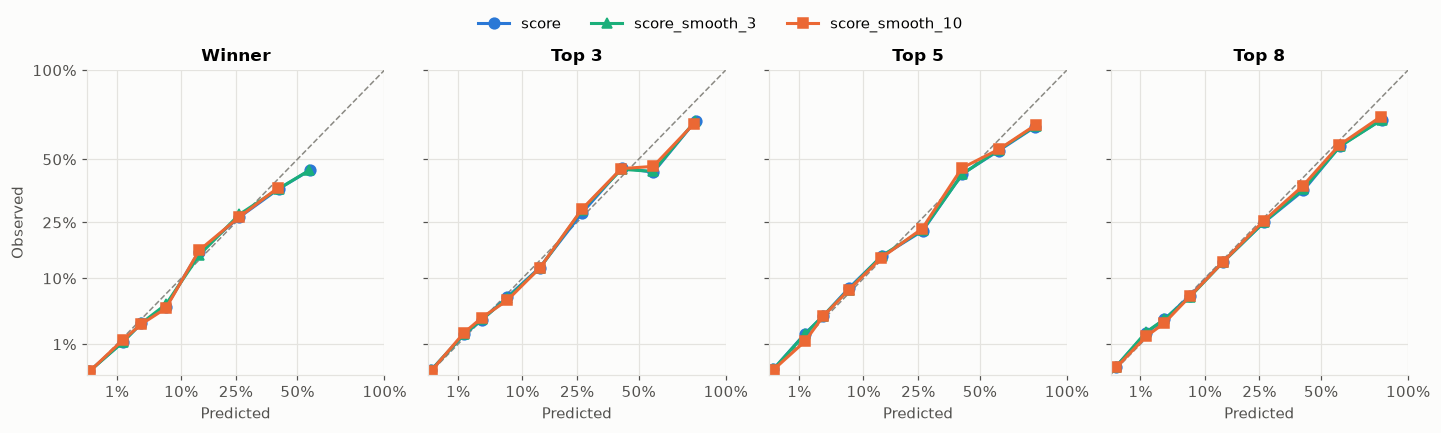

,model,n,bin,predicted,observed,count
0,score,1,"(-0.001, 0.01]",0.0001,0.0001,111281
1,score,1,"(0.01, 0.02]",0.0143,0.0114,439
2,score,1,"(0.02, 0.05]",0.0331,0.0282,496
3,score,1,"(0.05, 0.1]",0.0706,0.0496,242
4,score,1,"(0.1, 0.2]",0.1419,0.1635,208
5,score,1,"(0.2, 0.35]",0.2618,0.2672,131
6,score,1,"(0.35, 0.5]",0.4161,0.3729,59
7,score,1,"(0.5, 0.7]",0.5597,0.4500,20
8,score,1,"(0.7, 1.0]",0.7368,0.0000,1
9,score,3,"(-0.001, 0.01]",0.0001,0.0002,109778


In [9]:
MIN_BIN_COUNT = 20
TICKS = [0.01, 0.1, 0.25, 0.5, 1]
TICK_LABELS = ['1%', '10%', '25%', '50%', '100%']

calib = br.calibration(scored)
fig, axes = plt.subplots(1, len(TRADED), figsize=(3.3 * len(TRADED), 3.7), sharey=True)
for ax, n in zip(axes, TRADED):
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color=REFERENCE)
    for model in MODELS:
        g = calib[(calib['model'] == model) & (calib['n'] == n) & (calib['count'] >= MIN_BIN_COUNT)]
        ax.plot(g['predicted'], g['observed'], label=model, **MODEL_STYLES[model])
    ax.set_xscale('function', functions=(np.sqrt, np.square))
    ax.set_yscale('function', functions=(np.sqrt, np.square))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks(TICKS, TICK_LABELS); ax.set_yticks(TICKS, TICK_LABELS)
    ax.set_title(label_n(n))
    ax.set_xlabel('Predicted')
axes[0].set_ylabel('Observed')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout()
plt.show()

display(calib.drop(columns='run_id').round(4))

## 7. Attendance

Attendance is identical for all three models. The chart shows whether the model expected the right number of
pool players at each event.

,events,log_loss,predicted_players_per_event,actual_players_per_event
model,,,,
score,147,0.3257,124.0781,112.7823


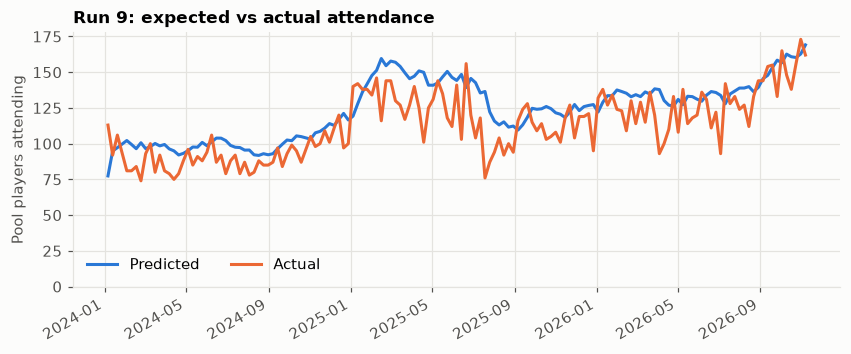

,bin,predicted,observed,count
0,"(-0.001, 0.01]",0.0052,0.0214,49765
1,"(0.01, 0.02]",0.0146,0.0571,4851
2,"(0.02, 0.05]",0.0339,0.0799,7555
3,"(0.05, 0.1]",0.0729,0.1012,7186
4,"(0.1, 0.2]",0.1480,0.1341,11047
5,"(0.2, 0.35]",0.2708,0.2186,12065
6,"(0.35, 0.5]",0.4220,0.3362,7692
7,"(0.5, 0.7]",0.5935,0.4776,6887
8,"(0.7, 1.0]",0.8398,0.6715,5829


In [10]:
display(br.attendance_summary(scored).loc[RUN_ID].loc[['score']].round(4))

one = scored[(scored['n'] == 1) & (scored['model'] == 'score')]
by_event = one.groupby('tourn_date').agg(predicted=('p_participate', 'sum'), actual=('played', 'sum'))
dates = pd.to_datetime(by_event.index)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(dates, by_event['predicted'], color='#2a78d6', label='Predicted')
ax.plot(dates, by_event['actual'], color='#eb6834', label='Actual')
ax.set_ylim(bottom=0)
ax.set_ylabel('Pool players attending')
ax.set_title(f'Run {RUN_ID}: expected vs actual attendance', loc='left')
ax.legend(loc='lower left', ncol=2)
fig.autofmt_xdate()
plt.show()

attendance_calib = br.calibration(one, probability='p_participate', outcome='played')
display(attendance_calib.drop(columns=['run_id', 'model', 'n']).round(4))

## 8. Where smoothing changes the predictions

Each point is one player at one event, against the unsmoothed model. On square-root axes, points above the
dashed line gained probability.

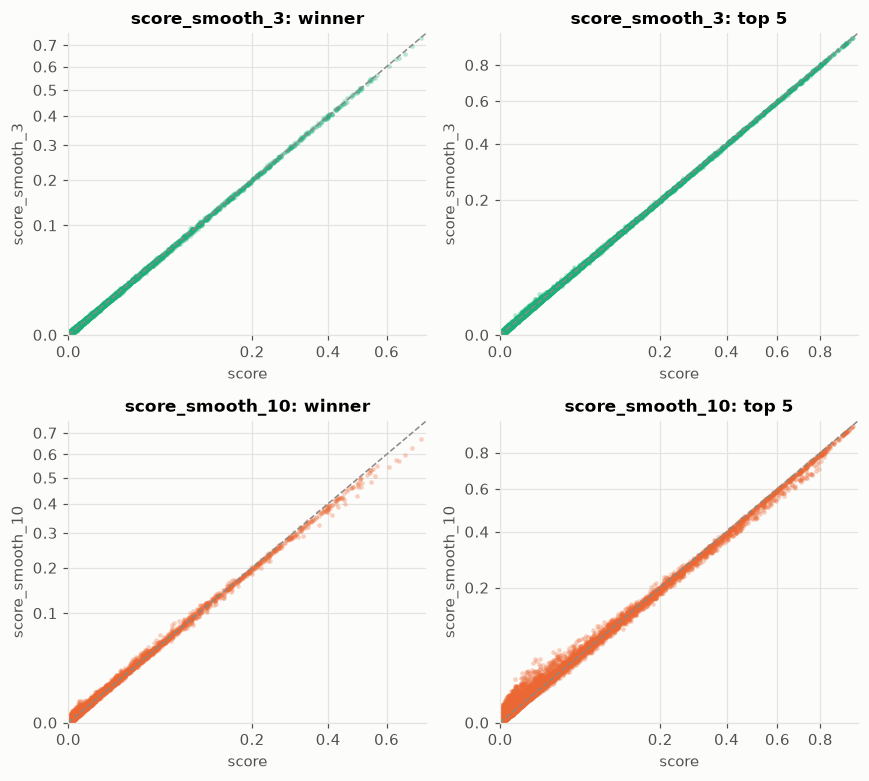

2026-11-07: chance of winning


,score,score_smooth_3,score_smooth_10,p_participate,played,actual_rank
username,,,,,,
hikaru,0.6712,0.6559,0.5972,0.9536,1,1.0
firouzja2003,0.0880,0.0954,0.0926,0.2500,0,NaN
oleksandr_bortnyk,0.0494,0.0504,0.0646,0.9967,1,5.0
gurelediz,0.0310,0.0325,0.0408,0.3792,1,2.0
ghandeevam2003,0.0278,0.0280,0.0348,0.3714,0,NaN
miterryble,0.0165,0.0171,0.0229,0.9984,1,12.0
christopheryoo,0.0158,0.0171,0.0158,0.2591,0,NaN
wonderfultime,0.0136,0.0139,0.0188,0.7303,1,8.0
jospem,0.0120,0.0129,0.0138,0.3664,1,27.0


In [11]:
wide = scored[scored['n'].isin([1, 5])].pivot_table(index=['n', 'tourn_date', 'username'], columns='model', values='p_top')
fig, axes = plt.subplots(2, 2, figsize=(8, 7.2))
for row, model in enumerate(SMOOTHED):
    for col, n in enumerate([1, 5]):
        ax, g = axes[row, col], wide.loc[n]
        limit = max(g['score'].max(), g[model].max()) * 1.03
        ax.scatter(g['score'], g[model], s=9, alpha=0.3, linewidths=0, color=MODEL_STYLES[model]['color'])
        ax.plot([0, limit], [0, limit], ls='--', lw=1, color=REFERENCE)
        ax.set_xscale('function', functions=(np.sqrt, np.square))
        ax.set_yscale('function', functions=(np.sqrt, np.square))
        ax.set_xlim(0, limit); ax.set_ylim(0, limit)
        ax.set_title(f'{model}: {label_n(n).lower()}')
        ax.set_xlabel('score'); ax.set_ylabel(model)
fig.tight_layout()
plt.show()

latest = scored['tourn_date'].max()
view = (scored[(scored['tourn_date'] == latest) & (scored['n'] == 1)]
        .pivot_table(index='username', columns='model', values='p_top')[MODELS]
        .join(predictions[(predictions['tourn_date'] == latest) & (predictions['model'] == 'score')]
              .set_index('username')[['p_participate', 'played', 'actual_rank']])
        .sort_values('score', ascending=False))
print(f'{latest}: chance of winning')
display(view.head(12).round(4))

## 9. Next event

The Monte Carlo pipeline on all loaded results, using `BULLET_BRAWL.model.score_noise_sigma`. Nothing is
saved to the database and no attendance adjustments are applied.

In [7]:
with contextlib.redirect_stdout(None):
    target = next_tourn_date(BULLET_BRAWL)
    forecast = run_raw(target, n_sims=N_SIMS, spec=BULLET_BRAWL).results_raw

print(f'{target}, sigma = {BULLET_BRAWL.model.score_noise_sigma} score points')
display(forecast.sort_values('P_top1', ascending=False)
        [['p_participate', 'P_top1', 'P_top3', 'P_top5', 'P_top8', 'P_top1_given_play']].head(45).round(4))

2026-11-14, sigma = 10.0 score points


,p_participate,P_top1,P_top3,P_top5,P_top8,P_top1_given_play
username,,,,,,
hikaru,0.9652,0.6022,0.9043,0.9484,0.9611,0.6235
firouzja2003,0.1875,0.0680,0.1672,0.1790,0.1812,0.3641
oleksandr_bortnyk,0.9976,0.0609,0.3312,0.5669,0.7830,0.0611
gurelediz,0.5344,0.0578,0.2789,0.4013,0.4779,0.1077
legendisback1,0.2506,0.0239,0.0671,0.1060,0.1556,0.0956
ghandeevam2003,0.2785,0.0237,0.1131,0.1569,0.1844,0.0856
miterryble,0.9988,0.0213,0.1476,0.3003,0.5031,0.0214
wonderfultime,0.7977,0.0197,0.1475,0.3016,0.4849,0.0247
jospem,0.5248,0.0183,0.0821,0.1475,0.2173,0.0349
